# Does the macroeconomy move the LuSE?

**Question:** how do GDP growth, inflation and the Kwacha exchange rate relate to the LuSE All Share Index (LASI)?

What I expect going in:
- **H1** GDP growth has a positive effect on the LASI
- **H2** inflation has a negative effect
- **H3** Kwacha depreciation has a negative effect
- **H4** the three together have a significant effect

Data are annual, with the LASI in natural logs (LLASI) and the exchange rate in natural logs (LEXR).

In [1]:
import json
import urllib.request
from datetime import date
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from arch.unitroot import PhillipsPerron
from scipy import stats
from statsmodels.stats.diagnostic import acorr_breusch_godfrey, het_breuschpagan, linear_reset
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import jarque_bera
from statsmodels.tsa.stattools import adfuller

import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})

OUT = Path("outputs")
OUT.mkdir(exist_ok=True)
for f in OUT.glob("*"):
    f.unlink()          # start each run with an empty outputs folder

## 1. Pull the data

GDP growth, inflation and the exchange rate come straight from the World Bank API (World Development Indicators, Zambia).
The LuSE has no API, so the LASI year-end closes sit in `data/lasi_year_end.csv` with the source of each figure.

In [2]:
def world_bank(indicator):
    url = f"https://api.worldbank.org/v2/country/ZMB/indicator/{indicator}?format=json&date=1997:{date.today().year}&per_page=100"
    with urllib.request.urlopen(url, timeout=30) as r:
        meta, rows = json.load(r)
    print(f"{indicator:20s} last updated {meta['lastupdated']}")
    return pd.Series({int(x["date"]): x["value"] for x in rows}, dtype=float).sort_index()

try:
    macro = pd.DataFrame({
        "GDPG": world_bank("NY.GDP.MKTP.KD.ZG"),   # real GDP growth, %
        "INFL":  world_bank("FP.CPI.TOTL.ZG"),      # CPI inflation, %
        "EXR":  world_bank("PA.NUS.FCRF"),         # ZMW per USD, annual average
    })
    macro.index.name = "Year"
    macro.to_csv("data/wdi_cache.csv")            # keep a copy in case I am offline next time
except OSError as e:
    print("API not reachable, using last saved pull:", e)
    macro = pd.read_csv("data/wdi_cache.csv", index_col="Year")

lasi = pd.read_csv("data/lasi_year_end.csv", index_col="Year")
data = macro.join(lasi["LASI"]).dropna()
data["LLASI"] = np.log(data["LASI"])
data["LEXR"] = np.log(data["EXR"])

START, END = 2000, int(data.index.max())
df = data.loc[START:END].copy()
print(f"\nSample: {START} to {END}, {len(df)} years")
df

NY.GDP.MKTP.KD.ZG    last updated 2026-11-11


FP.CPI.TOTL.ZG       last updated 2026-11-11


PA.NUS.FCRF          last updated 2026-11-11

Sample: 2000 to 2025, 26 years


,GDPG,INFL,EXR,LASI,LLASI,LEXR
Year,,,,,,
2000,3.897,26.030,3.111,305.260,5.721,1.135
2001,5.317,21.394,3.611,303.410,5.715,1.284
2002,4.506,22.233,4.399,334.750,5.813,1.481
2003,6.945,21.402,4.733,431.970,6.068,1.555
2004,7.032,17.968,4.779,765.750,6.641,1.564
2005,7.236,18.324,4.465,"1,240.220",7.123,1.496
2006,7.904,9.020,3.602,"1,837.610",7.516,1.281
2007,8.352,10.657,4.002,"3,533.520",8.170,1.387
2008,7.774,12.446,3.745,"2,505.880",7.826,1.320


**The World Bank already has 2025, so my sample runs 2000 to 2025 (26 years).**

All three World Bank series were last updated on 11 Nov 2026. The LASI closed 2025 at 25,919.83, which is 67.9% above the 2024 close of 15,440.90.

## 2. Look at the series first

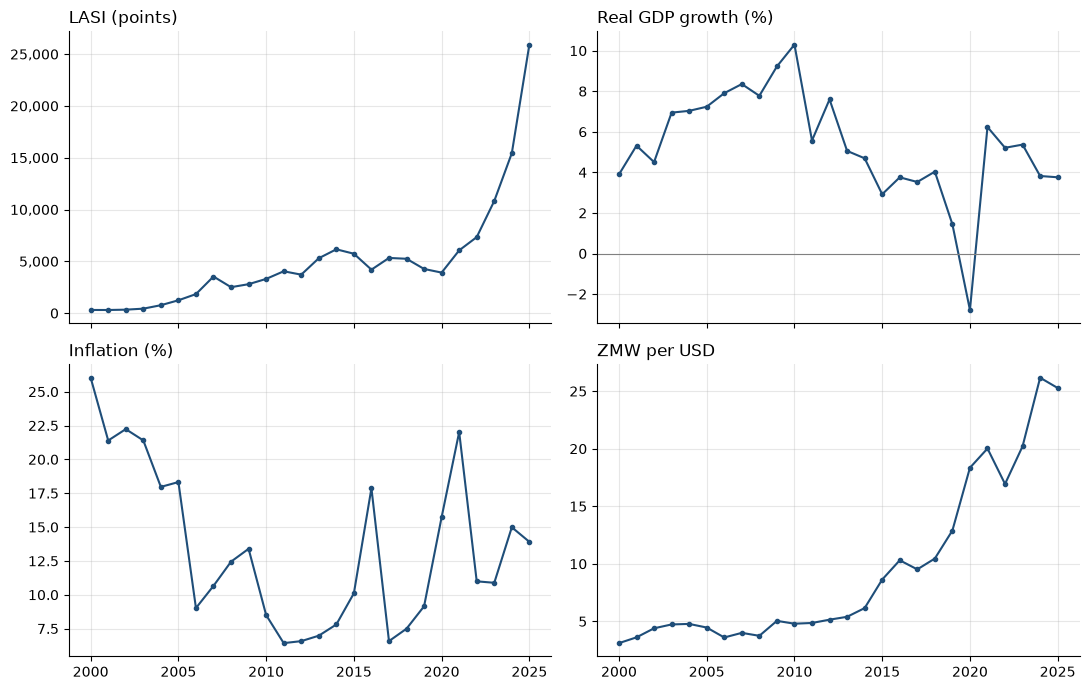

In [3]:
fig, ax = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for a, col, title in zip(ax.flat, ["LASI", "GDPG", "INFL", "EXR"],
                         ["LASI (points)", "Real GDP growth (%)", "Inflation (%)", "ZMW per USD"]):
    a.plot(df.index, df[col], marker="o", ms=3, color="#1f4e79")
    a.set_title(title, loc="left")
ax[0, 1].axhline(0, color="grey", lw=0.8)
ax[0, 0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
fig.tight_layout()
fig.savefig(OUT / "trends.png", dpi=200)
plt.show()

**The LASI rose from 305 to 25,920 points, with three clear setbacks.**

- The LASI fell in 2008 (3,534 to 2,506), in 2015 to 2016 (6,161 to 4,196) and again to 3,912 in 2020, before climbing every year from 2021.
- GDP growth peaked at 10.3% in 2010. 2020 is the only negative year (-2.8%).
- Inflation fell from 26.0% in 2000 to 6.4% in 2011, jumped back to 22.0% in 2021 and was 13.9% in 2025.
- The Kwacha moved from 3.11 per USD in 2000 to 26.17 in 2024 and 25.28 in 2025. Most of that depreciation came after 2014.

## 3. Descriptive statistics

In [4]:
def describe(s):
    jb, jb_p, skew, kurt = jarque_bera(s)
    return pd.Series({"Mean": s.mean(), "Median": s.median(), "Max": s.max(), "Min": s.min(),
                      "Std dev": s.std(), "Skewness": skew, "Kurtosis": kurt, "Jarque-Bera": jb, "JB p": jb_p})

desc = df[["LASI", "LLASI", "GDPG", "INFL", "EXR", "LEXR"]].apply(describe)
desc

,LASI,LLASI,GDPG,INFL,EXR,LEXR
Mean,"5,032.412",7.998,5.334,13.419,9.485,2.011
Median,"3,976.340",8.288,5.264,11.719,5.272,1.662
Max,"25,919.830",10.163,10.298,26.030,26.166,3.264
Min,303.410,5.715,-2.785,6.429,3.111,1.135
Std dev,"5,437.557",1.177,2.675,5.847,7.155,0.680
Skewness,2.495,-0.634,-0.774,0.542,1.132,0.575
Kurtosis,9.798,2.789,4.630,2.085,2.936,1.889
Jarque-Bera,77.030,1.787,5.473,2.178,5.560,2.769
JB p,0.000,0.409,0.065,0.337,0.062,0.250


**The raw LASI is far from normal, so I model it in logs.**

- LASI has skewness of 2.50 and kurtosis of 9.80, and Jarque-Bera rejects normality (p = 0.000). Its log, LLASI, passes (p = 0.409).
- GDP growth has kurtosis of 4.63 because of the 2020 contraction. It still passes Jarque-Bera at 5% (p = 0.065).
- Inflation averages 13.4%, with a standard deviation of 5.8 points.

## 4. Correlations

First in levels, then in year-on-year changes. Trending series can look correlated in levels just because they both trend,
so the changes are the fairer check.

In [5]:
vars_ = ["LLASI", "GDPG", "INFL", "LEXR"]

def corr_table(frame):
    frame = frame.dropna()
    r = frame.corr()
    p = r.copy()
    for a, b in product(vars_, vars_):
        p.loc[a, b] = stats.pearsonr(frame[a], frame[b])[1] if a != b else 0
    return r, p

r_lvl, p_lvl = corr_table(df[vars_])
r_chg, p_chg = corr_table(df[vars_].diff())

def star(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""

def with_stars(r, p):
    return pd.DataFrame([[f"{r.loc[a, b]:.3f}{star(p.loc[a, b])}" if a != b else "1" for b in vars_] for a in vars_],
                        index=vars_, columns=vars_)

print("Levels   (* p<0.10  ** p<0.05  *** p<0.01)")
display(with_stars(r_lvl, p_lvl))
print("Year-on-year changes")
display(with_stars(r_chg, p_chg))

Levels   (* p<0.10  ** p<0.05  *** p<0.01)


,LLASI,GDPG,INFL,LEXR
LLASI,1,-0.200,-0.621***,0.748***
GDPG,-0.200,1,-0.077,-0.546***
INFL,-0.621***,-0.077,1,-0.097
LEXR,0.748***,-0.546***,-0.097,1


Year-on-year changes


,LLASI,GDPG,INFL,LEXR
LLASI,1,0.218,-0.269,-0.331
GDPG,0.218,1,0.079,-0.151
INFL,-0.269,0.079,1,0.706***
LEXR,-0.331,-0.151,0.706***,1


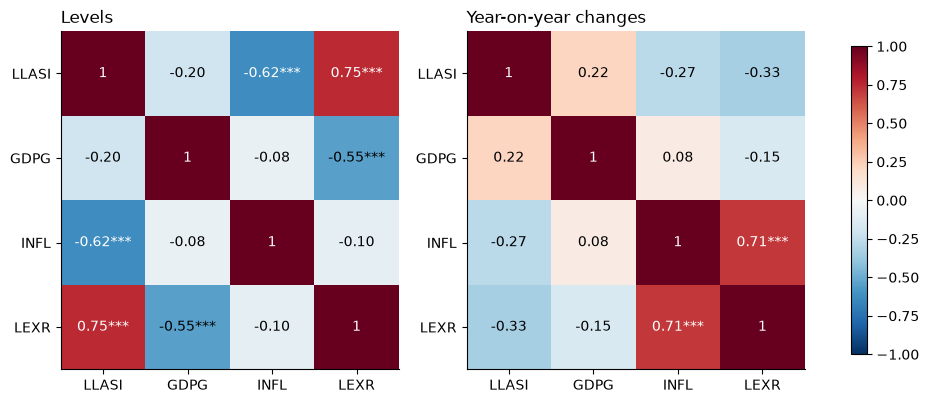

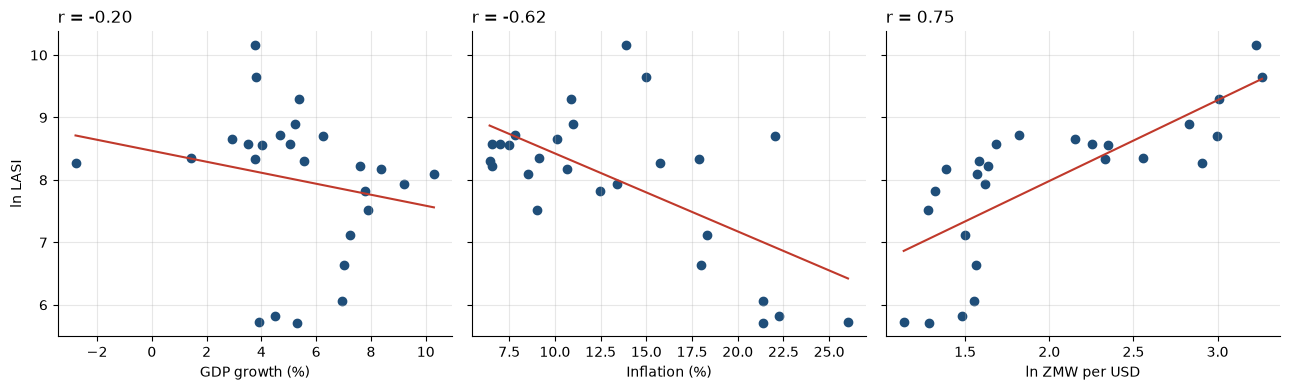

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for a, (r, p, title) in zip(axes, [(r_lvl, p_lvl, "Levels"), (r_chg, p_chg, "Year-on-year changes")]):
    im = a.imshow(r, cmap="RdBu_r", vmin=-1, vmax=1)
    a.set_xticks(range(4), vars_); a.set_yticks(range(4), vars_); a.grid(False)
    for i, j in product(range(4), range(4)):
        a.text(j, i, "1" if i == j else f"{r.iat[i, j]:.2f}{star(p.iat[i, j])}", ha="center", va="center",
               color="white" if abs(r.iat[i, j]) > 0.6 else "black")
    a.set_title(title, loc="left")
fig.colorbar(im, ax=axes, shrink=0.8)
fig.savefig(OUT / "correlations.png", dpi=200, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for a, x, lab in zip(axes, ["GDPG", "INFL", "LEXR"], ["GDP growth (%)", "Inflation (%)", "ln ZMW per USD"]):
    a.scatter(df[x], df["LLASI"], color="#1f4e79")
    b1, b0 = np.polyfit(df[x], df["LLASI"], 1)
    a.plot(df[x].sort_values(), b0 + b1 * df[x].sort_values(), color="#c0392b")
    a.set_xlabel(lab); a.set_title(f"r = {r_lvl.loc['LLASI', x]:.2f}", loc="left")
axes[0].set_ylabel("ln LASI")
fig.tight_layout()
fig.savefig(OUT / "scatter.png", dpi=200)
plt.show()

In [7]:
X = sm.add_constant(df[["GDPG", "INFL", "LEXR"]])
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(1, 4)], index=["GDPG", "INFL", "LEXR"], name="VIF")
vif

GDPG   1.459
INFL   1.035
LEXR   1.464
Name: VIF, dtype: float64

**In levels, the LASI moves with the exchange rate and against inflation. In year-on-year changes, none of its correlations are significant.**

- Levels: LLASI vs LEXR r = 0.748, LLASI vs INFL r = -0.621 (both p < 0.01). LLASI vs GDPG r = -0.200 is not significant.
- Changes: LLASI's correlations are -0.331 with LEXR, -0.269 with INFL and 0.218 with GDPG, none significant at 10%. That is why I don't read much into the levels figures on their own.
- In changes, inflation and the exchange rate move together (r = 0.706, p < 0.01). In levels, GDPG and LEXR are negatively correlated (r = -0.546).
- The highest VIF is 1.46, far below 10, so multicollinearity is not a problem for the regression.

## 5. Are the series stationary?

ADF and Phillips-Perron, in levels and first differences. This decides the method: if everything is I(1) I could use Johansen;
a mix of I(0) and I(1) points to ARDL bounds testing, as long as nothing is I(2).

In [8]:
rows = []
for v in vars_:
    for form, s in [("level", df[v]), ("1st diff", df[v].diff().dropna())]:
        for trend in ["c", "ct"]:
            adf = adfuller(s, maxlag=3, regression=trend, autolag="AIC")
            pp = PhillipsPerron(s, trend=trend)
            rows.append([v, form, trend, adf[0], adf[1], pp.stat, pp.pvalue])
ur = pd.DataFrame(rows, columns=["Variable", "Form", "Trend", "ADF", "ADF p", "PP", "PP p"])
display(ur)

# order of integration at 5% (intercept only)
c = ur[ur.Trend == "c"].set_index(["Variable", "Form"])
order = {v: "I(0)" if min(c.loc[(v, "level"), ["ADF p", "PP p"]]) < 0.05
         else "I(1)" if min(c.loc[(v, "1st diff"), ["ADF p", "PP p"]]) < 0.05 else "I(2)?" for v in vars_}
order

,Variable,Form,Trend,ADF,ADF p,PP,PP p
0,LLASI,level,c,-0.764,0.829,-0.762,0.829
1,LLASI,level,ct,-1.463,0.841,-1.476,0.838
2,LLASI,1st diff,c,-3.659,0.005,-3.674,0.005
3,LLASI,1st diff,ct,-3.585,0.031,-3.567,0.033
4,GDPG,level,c,-2.584,0.096,-2.882,0.047
5,GDPG,level,ct,-3.291,0.068,-3.139,0.097
6,GDPG,1st diff,c,-7.024,0.000,-8.184,0.000
7,GDPG,1st diff,ct,-6.902,0.000,-8.156,0.000
8,INFL,level,c,-2.972,0.038,-2.935,0.041
9,INFL,level,ct,-2.703,0.235,-2.532,0.312


{'LLASI': 'I(1)', 'GDPG': 'I(0)', 'INFL': 'I(0)', 'LEXR': 'I(1)'}

**LLASI and LEXR are I(1), GDPG and INFL are I(0), and nothing is I(2), so ARDL bounds testing fits and Johansen does not.**

- LLASI and LEXR do not reject a unit root in levels (ADF p = 0.829 and 0.973) but do in first differences (p = 0.005 and 0.000).
- INFL rejects in levels with an intercept (ADF p = 0.038, PP p = 0.041).
- GDPG is borderline: PP rejects in levels (p = 0.047) and ADF does not (p = 0.096). Either way it is I(1) at most, so the choice of method does not change.

## 6. Choose the lag structure

I try every ARDL(p, q1, q2, q3) with up to 2 lags and keep the one with the lowest AIC.
All models are fitted on the same years so the AIC values are comparable.

In [9]:
d = df.copy()
for v in vars_:
    for k in (1, 2):
        d[f"{v}_{k}"] = d[v].shift(k)

def ardl_formula(p, q):
    terms = [f"LLASI_{i}" for i in range(1, p + 1)]
    for x, qx in zip(["GDPG", "INFL", "LEXR"], q):
        terms += [x] + [f"{x}_{j}" for j in range(1, qx + 1)]
    return "LLASI ~ " + " + ".join(terms)

est = d.loc[START + 2:]      # drop the first two years so every model uses the same sample
aic = []
for p in (1, 2):
    for q in product((0, 1, 2), repeat=3):
        m = smf.ols(ardl_formula(p, q), est).fit()
        aic.append((f"ARDL({p}, {q[0]}, {q[1]}, {q[2]})", (-2 * m.llf + 2 * (m.df_model + 1)) / m.nobs, p, q))
aic = pd.DataFrame(aic, columns=["Model", "AIC", "p", "q"]).sort_values("AIC").reset_index(drop=True)
aic[["Model", "AIC"]].head(6)

,Model,AIC
0,"ARDL(1, 0, 0, 0)",0.090
1,"ARDL(2, 0, 0, 0)",0.131
2,"ARDL(1, 0, 0, 2)",0.133
3,"ARDL(1, 1, 0, 0)",0.152
4,"ARDL(1, 0, 0, 1)",0.157
5,"ARDL(1, 0, 1, 0)",0.174


**AIC picks ARDL(1, 0, 0, 0): one lag of the LASI and only current values of the three macro variables.**

Its AIC is 0.090. The next best are ARDL(2, 0, 0, 0) at 0.131 and ARDL(1, 0, 0, 2) at 0.133. The estimation sample is 2002 to 2025 (n = 24).

## 7. Estimate the ARDL model

In [10]:
p, q = aic.loc[0, "p"], aic.loc[0, "q"]
ardl = smf.ols(ardl_formula(p, q), est).fit()
print(ardl.summary())

                            OLS Regression Results                            
Dep. Variable:                  LLASI   R-squared:                       0.957
Model:                            OLS   Adj. R-squared:                  0.947
Method:                 Least Squares   F-statistic:                     104.7
Date:                Mon, 23 Nov 2026   Prob (F-statistic):           1.15e-12
Time:                        21:05:57   Log-Likelihood:                 3.9176
No. Observations:                  24   AIC:                             2.165
Df Residuals:                      19   BIC:                             8.055
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.3586      0.763      1.780      0.0

**The model explains 95.7% of the variation in ln LASI (adjusted R-squared 0.947).**

- Last year's LASI carries strongly into this year (coefficient 0.721, p < 0.001).
- GDP growth (0.065, p = 0.009) and the exchange rate (0.496, p = 0.007) are significant in the same year.
- Inflation is negative but not significant within the year (-0.026, p = 0.116).

## 8. Bounds test: is there a long-run relationship?

I rewrite the model in error-correction form and test whether the lagged level of LLASI and the levels of the three
regressors are jointly zero (Pesaran, Shin and Smith, 2001, case III: unrestricted intercept, no trend).

In [11]:
# AIC picked ARDL(1, 0, 0, 0), so the EC form has no short-run difference terms
assert (p, q) == (1, (0, 0, 0)), "different lag structure selected: add its short-run terms here"
est = est.assign(D_LLASI=est["LLASI"] - est["LLASI_1"])
ec =smf.ols("D_LLASI ~ LLASI_1 + GDPG + INFL + LEXR", est).fit()
F = float(ec.f_test("LLASI_1 = 0, GDPG = 0, INFL = 0, LEXR = 0").fvalue)

bounds = pd.DataFrame({"I(0)": [2.72, 3.23, 4.29], "I(1)": [3.77, 4.35, 5.61]}, index=["10%", "5%", "1%"])
print(f"Bounds F = {F:.3f}  (k = 3, n = {int(ec.nobs)})")
bounds

Bounds F = 3.363  (k = 3, n = 24)


,I(0),I(1)
10%,2.720,3.770
5%,3.230,4.350
1%,4.290,5.610


**The bounds test is inconclusive: F = 3.363 falls between the lower and upper bounds at both 10% and 5%.**

At 10% the bounds are 2.72 and 3.77; at 5% they are 3.23 and 4.35. I cannot confirm or rule out a long-run relationship from this test alone, so I read the long-run coefficients below with that limit in mind. The error correction term in step 10 is a second check.

## 9. Long-run coefficients

Long-run effect of each variable = minus its level coefficient divided by the coefficient on LLASI(-1).
Standard errors by the delta method.

In [12]:
lam = ec.params["LLASI_1"]
V = ec.cov_params()
lr = []
for x in ["GDPG", "INFL", "LEXR"]:
    b = -ec.params[x] / lam
    grad = pd.Series(0.0, index=ec.params.index)
    grad[x], grad["LLASI_1"] = -1 / lam, ec.params[x] / lam**2
    se = np.sqrt(grad @ V @ grad)
    lr.append([x, b, se, b / se, 2 * stats.t.sf(abs(b / se), ec.df_resid)])
longrun = pd.DataFrame(lr, columns=["Variable", "Coef", "Std err", "t", "p"]).set_index("Variable")
longrun

,Coef,Std err,t,p
Variable,,,,
GDPG,0.233,0.108,2.153,0.044
INFL,-0.092,0.035,-2.629,0.017
LEXR,1.777,0.383,4.639,0.000


**In the long run, growth lifts the LASI, inflation pulls it down, and a weaker Kwacha goes with a higher LASI.**

- **GDPG 0.233 (p = 0.044):** each extra percentage point of GDP growth goes with a LASI about 26% higher (e^0.233 - 1).
- **INFL -0.092 (p = 0.017):** each extra point of inflation goes with a LASI about 9% lower (e^-0.092 - 1).
- **LEXR 1.777 (p < 0.001):** a 1% rise in ZMW per USD goes with a 1.78% rise in the LASI. This is the opposite of the sign I expected.

## 10. Speed of adjustment

In [13]:
ect, ect_p = lam, ec.pvalues["LLASI_1"]
half_life = np.log(0.5) / np.log(1 + ect)
print(f"Error correction term = {ect:.3f} (p = {ect_p:.3f})")
print(f"{abs(ect):.1%} of a gap from the long-run path closes each year; half-life about {half_life:.1f} years")

Error correction term = -0.279 (p = 0.017)
27.9% of a gap from the long-run path closes each year; half-life about 2.1 years


**The error correction term is negative and significant, so the LASI returns to its long-run path: about 28% of any gap closes each year.**

The ECT is -0.279 (p = 0.017), and a gap halves in about 2.1 years. A negative, significant ECT supports the long-run relationship that the bounds test could not settle.

## 11. Joint effect (H4)

In [14]:
x_terms = [t for t in ardl.params.index if t.split("_")[0] in ("GDPG", "INFL", "LEXR")]
wald = ardl.f_test(", ".join(f"{t} = 0" for t in x_terms))
print(f"Wald F({int(wald.df_num)}, {int(wald.df_denom)}) = {float(wald.fvalue):.3f}, p = {float(wald.pvalue):.3f}")

Wald F(3, 19) = 3.870, p = 0.026


**Together, the three variables are significant: F(3, 19) = 3.870, p = 0.026.**

## 12. Is the model sound? Residual checks and stability

In [15]:
bg = acorr_breusch_godfrey(ardl, nlags=2)
bp = het_breuschpagan(ardl.resid, ardl.model.exog)
jb = jarque_bera(ardl.resid)
reset = linear_reset(ardl, power=2, use_f=True)
checks = pd.DataFrame({
    "Stat": [bg[2], bp[2], jb[0], float(reset.fvalue)],
    "p":    [bg[3], bp[3], jb[1], float(reset.pvalue)],
}, index=["Serial correlation (BG LM, 2 lags)", "Heteroskedasticity (BPG)", "Normality (JB)", "Functional form (RESET)"])
checks["OK at 5%"] = checks["p"] > 0.05
display(checks)

z = ardl.resid / np.sqrt(ardl.scale)
print("Years with |standardised residual| > 2:", list(z[abs(z) > 2].index) or "none")

,Stat,p,OK at 5%
"Serial correlation (BG LM, 2 lags)",0.017,0.984,True
Heteroskedasticity (BPG),0.675,0.617,True
Normality (JB),1.247,0.536,True
Functional form (RESET),0.211,0.651,True


Years with |standardised residual| > 2: none


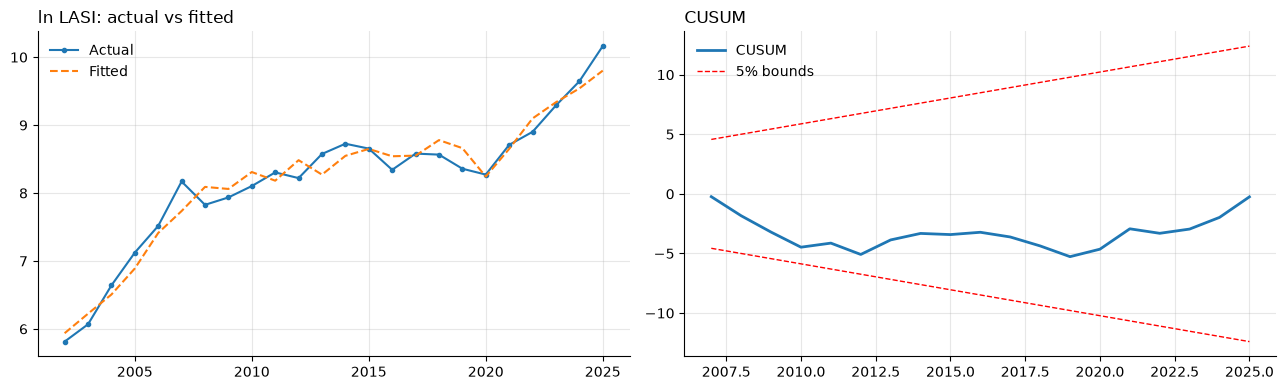

CUSUM inside 5% bounds: True


In [16]:
rls = sm.RecursiveLS(ardl.model.endog, ardl.model.exog).fit()
m = len(rls.cusum)
bound = 0.948 * np.sqrt(m) + 2 * 0.948 * np.arange(1, m + 1) / np.sqrt(m)
cusum_ok = bool(np.all(np.abs(rls.cusum) <= bound))
yrs = est.index[-m:]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(est.index, est["LLASI"], marker="o", ms=3, label="Actual")
ax[0].plot(est.index, ardl.fittedvalues, "--", label="Fitted")
ax[0].set_title("ln LASI: actual vs fitted", loc="left"); ax[0].legend(frameon=False)
ax[1].plot(yrs, rls.cusum, lw=2, label="CUSUM")
ax[1].plot(yrs, bound, "r--", lw=1, label="5% bounds"); ax[1].plot(yrs, -bound, "r--", lw=1)
ax[1].set_title("CUSUM", loc="left"); ax[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT / "fit_and_cusum.png", dpi=200)
plt.show()
print("CUSUM inside 5% bounds:", cusum_ok)

**The model passes every residual check and is stable over the sample.**

- Serial correlation p = 0.984, heteroskedasticity p = 0.617, normality p = 0.536, RESET p = 0.651.
- No year has a standardised residual beyond plus or minus 2.
- CUSUM stays inside the 5% bounds throughout, so I see no sign of a structural break.

## 13. Does it hold on a different sample?

I wrap steps 6 to 11 into one function and rerun it on (a) the sample without the latest year and (b) a longer sample from 1997.

In [17]:
def run(frame):
    d = frame.copy()
    for v in vars_:
        for k in (1, 2):
            d[f"{v}_{k}"] = d[v].shift(k)
    e = d.iloc[2:].copy()
    e["D_LLASI"] = e["LLASI"] - e["LLASI_1"]
    fits = {(p, q): smf.ols(ardl_formula(p, q), e).fit() for p in (1, 2) for q in product((0, 1, 2), repeat=3)}
    best = min(fits, key=lambda k: (-2 * fits[k].llf + 2 * (fits[k].df_model + 1)) / fits[k].nobs)
    a = fits[best]
    assert best == (1, (0, 0, 0)), f"AIC picked {best}: the EC form below needs short-run terms added"
    u = smf.ols("D_LLASI ~ LLASI_1 + GDPG + INFL + LEXR", e).fit()
    l = u.params["LLASI_1"]
    xt = [t for t in a.params.index if t.split("_")[0] in ("GDPG", "INFL", "LEXR")]
    w = a.f_test(", ".join(f"{t} = 0" for t in xt))
    out = {"Years": f"{e.index.min()} to {e.index.max()} (n={int(a.nobs)})", "Model": f"ARDL({best[0]}, {', '.join(map(str, best[1]))})",
           "Bounds F": round(float(u.f_test("LLASI_1 = 0, GDPG = 0, INFL = 0, LEXR = 0").fvalue), 3)}
    for x in ("GDPG", "INFL", "LEXR"):
        out[f"LR {x}"] = round(-u.params[x] / l, 3)
    out["ECT"] = f"{l:.3f} (p {u.pvalues['LLASI_1']:.3f})"
    out["Wald F"] = f"{float(w.fvalue):.3f} (p {float(w.pvalue):.3f})"
    return out

robust = pd.DataFrame({
    f"{START} to {END}": run(data.loc[START:END]),
    f"{START} to {END - 1}": run(data.loc[START:END - 1]),
    f"1997 to {END}": run(data.loc[1997:END]),
})
robust

,2000 to 2025,2000 to 2024,1997 to 2025
Years,2002 to 2025 (n=24),2002 to 2024 (n=23),1999 to 2025 (n=27)
Model,"ARDL(1, 0, 0, 0)","ARDL(1, 0, 0, 0)","ARDL(1, 0, 0, 0)"
Bounds F,3.363,4.091,2.896
LR GDPG,0.233,0.192,0.220
LR INFL,-0.092,-0.095,-0.072
LR LEXR,1.777,1.506,1.672
ECT,-0.279 (p 0.017),-0.318 (p 0.006),-0.254 (p 0.026)
Wald F,3.870 (p 0.026),3.989 (p 0.024),3.403 (p 0.036)


**The signs and sizes hold on all three samples. What moves is the bounds test, and it moves with 2025.**

- Without 2025 (2002 to 2024), F = 4.091 is above the 10% upper bound (3.77), so that sample shows a long-run relationship at 10%. Adding 2025 drops F to 3.363.
- Starting in 1997 gives F = 2.896, also inconclusive.
- Long-run GDPG stays between 0.19 and 0.23, INFL between -0.07 and -0.10, and LEXR between 1.51 and 1.78. The ECT is negative and significant in all three samples (-0.25 to -0.32).

## 14. Where the hypotheses land

In [18]:
expect = {"GDPG": "+", "INFL": "-", "LEXR": "-"}
rows = []
for h, x in zip(["H1", "H2", "H3"], ["GDPG", "INFL", "LEXR"]):
    b, pv = longrun.loc[x, "Coef"], longrun.loc[x, "p"]
    sign_ok = (b > 0) == (expect[x] == "+")
    rows.append([h, x, expect[x], round(b, 3), round(pv, 3),
                 "Supported" if pv < 0.05 and sign_ok else "Rejected: significant but opposite sign" if pv < 0.05 else "Not supported"])
rows.append(["H4", "joint", "", round(float(wald.fvalue), 3), round(float(wald.pvalue), 3),
             "Supported" if float(wald.pvalue) < 0.05 else "Not supported"])
hyp = pd.DataFrame(rows, columns=["H", "Variable", "Expected", "Long-run coef / F", "p", "Result"])
hyp

,H,Variable,Expected,Long-run coef / F,p,Result
0,H1,GDPG,+,0.233,0.044,Supported
1,H2,INFL,-,-0.092,0.017,Supported
2,H3,LEXR,-,1.777,0.000,Rejected: significant but opposite sign
3,H4,joint,,3.870,0.026,Supported


## 15. Save tables

In [19]:
with pd.ExcelWriter(OUT / "results.xlsx") as xl:
    df.to_excel(xl, sheet_name="Data")
    desc.to_excel(xl, sheet_name="Descriptives")
    r_lvl.to_excel(xl, sheet_name="Corr levels")
    r_chg.to_excel(xl, sheet_name="Corr changes")
    vif.to_excel(xl, sheet_name="VIF")
    ur.to_excel(xl, sheet_name="Unit roots", index=False)
    aic[["Model", "AIC"]].to_excel(xl, sheet_name="Lag selection", index=False)
    pd.DataFrame({"Coef": ardl.params, "Std err": ardl.bse, "p": ardl.pvalues}).to_excel(xl, sheet_name="ARDL")
    longrun.to_excel(xl, sheet_name="Long run")
    checks.to_excel(xl, sheet_name="Diagnostics")
    robust.to_excel(xl, sheet_name="Robustness")
    hyp.to_excel(xl, sheet_name="Hypotheses", index=False)
sorted(p.name for p in OUT.iterdir())

['correlations.png',
 'fit_and_cusum.png',
 'results.xlsx',
 'scatter.png',
 'trends.png']

## What I found

- **H1 supported:** GDP growth has a positive long-run effect on the LASI (0.233, p = 0.044).
- **H2 supported:** inflation has a negative long-run effect (-0.092, p = 0.017).
- **H3 rejected:** Kwacha depreciation is significant but positive (1.777, p < 0.001), not negative.
- **H4 supported:** the three are jointly significant (F = 3.870, p = 0.026).
- **Long-run relationship:** the bounds test is inconclusive on 2000 to 2025 (F = 3.363). The negative, significant ECT (-0.279) and the 2000 to 2024 result (F = 4.091, significant at 10%) both point towards one.
- **The model holds up:** adjusted R-squared is 0.947, all diagnostics pass and CUSUM is stable.